# Setup & Load Untouched Raw Data (Kaggle CSV)

In [8]:
import glob
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    root_mean_squared_error, mean_absolute_error,
    mean_absolute_percentage_error, r2_score
)
from lightgbm import LGBMRegressor
import shap

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
os.makedirs("outputs", exist_ok=True)

# Automatically locate the downloaded CSV in data/raw/
search_dirs = ["data/raw", "../data/raw"]
csv_files = []
for d in search_dirs:
    if os.path.exists(d):
        csv_files.extend(glob.glob(os.path.join(d, "*.csv")))

# Prefer train.csv or Zomato*.csv over test/sample_submission
target_csv = None
for f in csv_files:
    fname = os.path.basename(f).lower()
    if "train" in fname or "zomato" in fname or "delivery" in fname:
        target_csv = f
        break
if target_csv is None and csv_files:
    target_csv = csv_files[0]

print(f"Loading raw dataset from: {target_csv}")
df_raw = pd.read_csv(target_csv)
print(f"Raw Dataset Shape: {df_raw.shape[0]:,} rows, {df_raw.shape[1]} columns")
df_raw.head()

Loading raw dataset from: ../data/raw\train.csv
Raw Dataset Shape: 45,593 rows, 20 columns


,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min)
0,0x4607,INDORES13DEL02,37,4.9,22.745049,75.892471,22.765049,75.912471,19-03-2022,11:30:00,11:45:00,conditions Sunny,High,2,Snack,motorcycle,0,No,Urban,(min) 24
1,0xb379,BANGRES18DEL02,34,4.5,12.913041,77.683237,13.043041,77.813237,25-03-2022,19:45:00,19:50:00,conditions Stormy,Jam,2,Snack,scooter,1,No,Metropolitian,(min) 33
2,0x5d6d,BANGRES19DEL01,23,4.4,12.914264,77.678400,12.924264,77.688400,19-03-2022,08:30:00,08:45:00,conditions Sandstorms,Low,0,Drinks,motorcycle,1,No,Urban,(min) 26
3,0x7a6a,COIMBRES13DEL02,38,4.7,11.003669,76.976494,11.053669,77.026494,05-04-2022,18:00:00,18:10:00,conditions Sunny,Medium,0,Buffet,motorcycle,1,No,Metropolitian,(min) 21
4,0x70a2,CHENRES12DEL01,32,4.6,12.972793,80.249982,13.012793,80.289982,26-03-2022,13:30:00,13:45:00,conditions Cloudy,High,1,Snack,scooter,1,No,Metropolitian,(min) 30


# EDA 1: Schema, Hidden String "NaN" Audit & Target Format Inspection (Sebelum Cleaning)

In [9]:
# Standardize target column name for inspection (handles 'Time_taken(min)' or 'Time_taken (min)')
target_col = [c for c in df_raw.columns if "Time_taken" in c][0]
print(f"Detected Target Column: '{target_col}' | Sample raw values: {df_raw[target_col].head(3).tolist()}")

audit_records = []
for col in df_raw.columns:
    std_nulls = df_raw[col].isnull().sum()
    # Count hidden string "NaN" or blank spaces common in raw logistics logs
    str_nan_count = (
        df_raw[col].astype(str).str.strip().isin(["NaN", "nan", "NULL", ""]).sum()
        if df_raw[col].dtype == "object"
        else 0
    )
    audit_records.append({
        "Column": col,
        "Dtype": str(df_raw[col].dtype),
        "Std_Nulls": std_nulls,
        "Hidden_String_NaN": str_nan_count,
        "Unique_Values": df_raw[col].nunique(),
        "Sample_Values": str(df_raw[col].dropna().unique()[:3]),
    })

display(pd.DataFrame(audit_records))

Detected Target Column: 'Time_taken(min)' | Sample raw values: ['(min) 24', '(min) 33', '(min) 26']


,Column,Dtype,Std_Nulls,Hidden_String_NaN,Unique_Values,Sample_Values
0,ID,str,0,0,45593,"<StringArray>\n['0x4607 ', '0xb379 ', '0x5d6d ..."
1,Delivery_person_ID,str,0,0,1320,"<StringArray>\n['INDORES13DEL02 ', 'BANGRES18D..."
2,Delivery_person_Age,str,0,0,23,"<StringArray>\n['37', '34', '23']\nLength: 3, ..."
3,Delivery_person_Ratings,str,0,0,29,"<StringArray>\n['4.9', '4.5', '4.4']\nLength: ..."
4,Restaurant_latitude,float64,0,0,657,[22.745049 12.913041 12.914264]
5,Restaurant_longitude,float64,0,0,518,[75.892471 77.683237 77.6784 ]
6,Delivery_location_latitude,float64,0,0,4373,[22.765049 13.043041 12.924264]
7,Delivery_location_longitude,float64,0,0,4373,[75.912471 77.813237 77.6884 ]
8,Order_Date,str,0,0,44,"<StringArray>\n['19-03-2022', '25-03-2022', '0..."
9,Time_Orderd,str,0,0,177,"<StringArray>\n['11:30:00', '19:45:00', '08:30..."


# EDA 2: GPS Coordinate Corruption, Rating Outliers & Traffic/Weather Impact

1. GPS Zero-Coordinate Rows (0.0, 0.0)      : 3,640 rows
2. GPS Negative-Sign Corrupted Rows         : 431 rows
3. Impossible Courier Ratings (> 5.0 scale) : 53 rows (Max rating: 6.0)


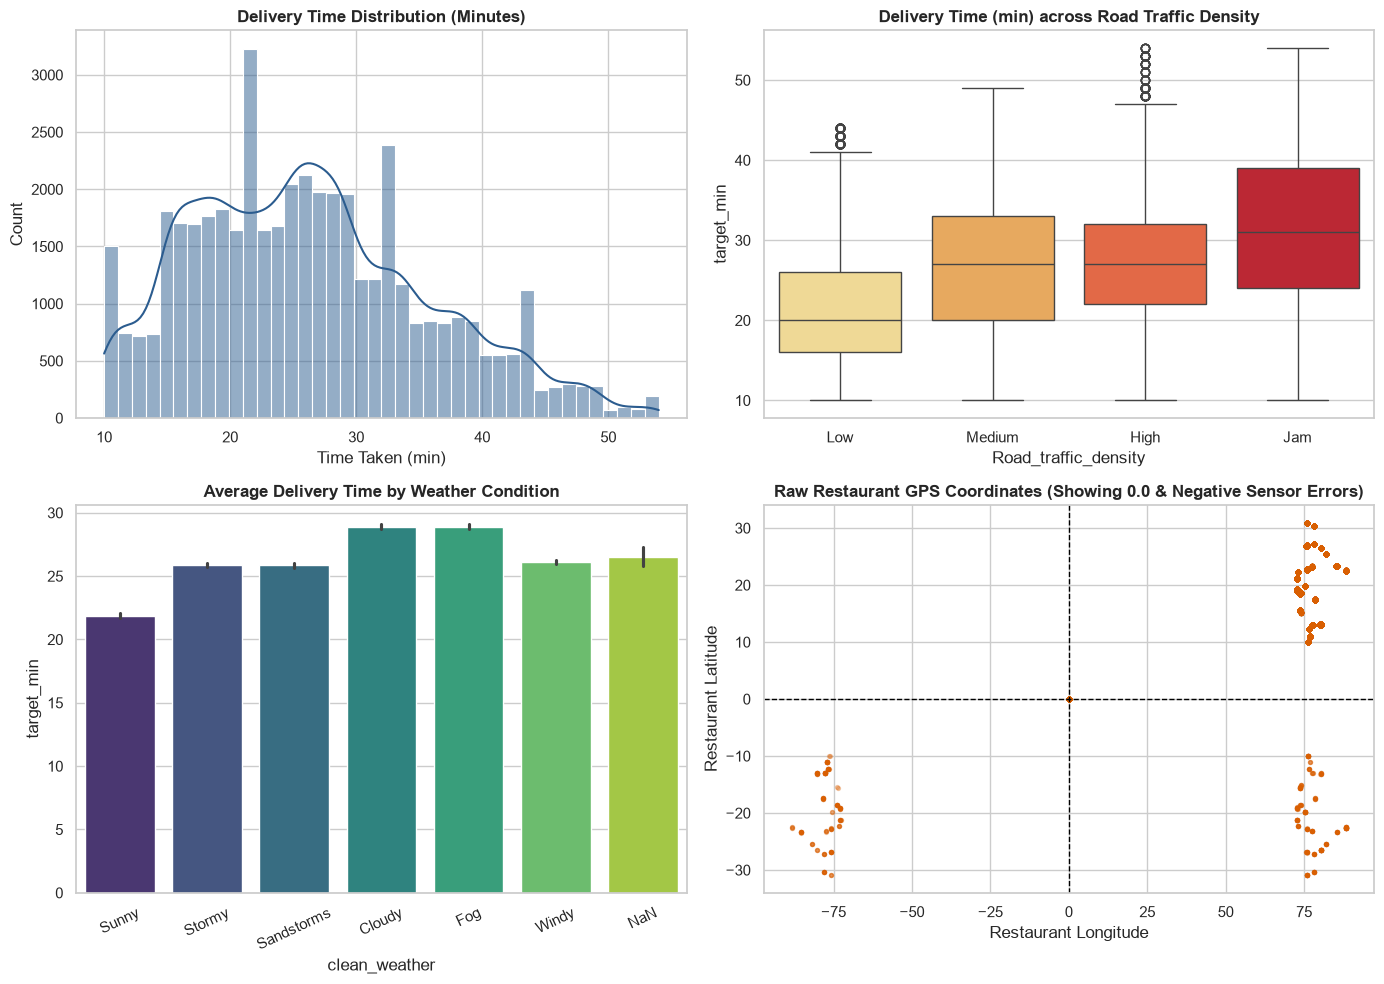

In [10]:
# Create temporary numeric copies solely for EDA profiling without mutating df_raw
temp_df = df_raw.copy()
for col in temp_df.select_dtypes(include="object").columns:
    temp_df[col] = temp_df[col].astype(str).str.strip().replace({"NaN": np.nan, "nan": np.nan, "": np.nan})

temp_df["age_num"] = pd.to_numeric(temp_df["Delivery_person_Age"], errors="coerce")
temp_df["rating_num"] = pd.to_numeric(temp_df["Delivery_person_Ratings"], errors="coerce")
temp_df["target_min"] = (
    temp_df[target_col].astype(str).str.replace("(min)", "", regex=False).str.strip()
)
temp_df["target_min"] = pd.to_numeric(temp_df["target_min"], errors="coerce")

# 1. Check GPS coordinate corruption (Zero coordinates or inverted negative signs in India: Lat 8N-37N, Lon 68E-97E)
zero_coords = (
    (temp_df["Restaurant_latitude"].abs() < 1.0) |
    (temp_df["Restaurant_longitude"].abs() < 1.0)
)
neg_coords = (temp_df["Restaurant_latitude"] < 0) | (temp_df["Restaurant_longitude"] < 0)
invalid_ratings = temp_df["rating_num"] > 5.0

print(f"1. GPS Zero-Coordinate Rows (0.0, 0.0)      : {zero_coords.sum():,} rows")
print(f"2. GPS Negative-Sign Corrupted Rows         : {neg_coords.sum():,} rows")
print(f"3. Impossible Courier Ratings (> 5.0 scale) : {invalid_ratings.sum():,} rows (Max rating: {temp_df['rating_num'].max()})")

# Visual EDA Dashboard
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot 1: Delivery Time Distribution
sns.histplot(temp_df["target_min"].dropna(), bins=40, kde=True, color="#2b5c8f", ax=axes[0, 0])
axes[0, 0].set_title("Delivery Time Distribution (Minutes)", fontweight="bold")
axes[0, 0].set_xlabel("Time Taken (min)")

# Plot 2: Delivery Time by Road Traffic Density
traffic_order = ["Low", "Medium", "High", "Jam"]
avail_traffic = [t for t in traffic_order if t in temp_df["Road_traffic_density"].dropna().unique()]
sns.boxplot(
    data=temp_df, x="Road_traffic_density", y="target_min",
    order=avail_traffic, palette="YlOrRd", ax=axes[0, 1]
)
axes[0, 1].set_title("Delivery Time (min) across Road Traffic Density", fontweight="bold")

# Plot 3: Delivery Time by Weather Conditions & Multiple Deliveries
weather_col = "Weatherconditions" if "Weatherconditions" in temp_df.columns else "Weather_conditions"
temp_df["clean_weather"] = temp_df[weather_col].astype(str).str.replace("conditions ", "", regex=False).str.strip()
sns.barplot(
    data=temp_df.dropna(subset=["clean_weather", "target_min"]),
    x="clean_weather", y="target_min", palette="viridis", ax=axes[1, 0]
)
axes[1, 0].set_title("Average Delivery Time by Weather Condition", fontweight="bold")
axes[1, 0].tick_params(axis="x", rotation=25)

# Plot 4: Raw GPS Coordinates Showing Sensor Corruption (Negative & Zero Lat/Lon)
axes[1, 1].scatter(temp_df["Restaurant_longitude"], temp_df["Restaurant_latitude"], alpha=0.3, s=8, color="#d95f02")
axes[1, 1].axhline(0, color="black", linestyle="--", linewidth=1)
axes[1, 1].axvline(0, color="black", linestyle="--", linewidth=1)
axes[1, 1].set_title("Raw Restaurant GPS Coordinates (Showing 0.0 & Negative Sensor Errors)", fontweight="bold")
axes[1, 1].set_xlabel("Restaurant Longitude")
axes[1, 1].set_ylabel("Restaurant Latitude")

plt.tight_layout()
plt.savefig("outputs/eda_delivery_time.png", dpi=150)
plt.show()

# Evidence-Based Data Cleaning

In [11]:
"""
Cleaning Rules Driven by EDA Findings:
1. Strip leading/trailing whitespace across all string columns and convert literal '"NaN"' strings to np.nan.
2. Parse target column ('Time_taken(min)') by stripping '(min)' prefix and casting to float.
3. Cap/nullify impossible courier ratings (> 5.0, e.g., 6.0) so they are properly imputed without distorting scale.
4. Fix inverted negative GPS coordinates via abs() (since all cities in this dataset are in India: 8°N–37°N, 68°E–97°E),
   and mark (0.0, 0.0) GPS dropouts as NaN after computing Haversine distance so extreme 8,000 km distances don't corrupt training.
"""
df_clean = df_raw.copy()

# 1. Strip whitespace and standardize hidden 'NaN' strings
for col in df_clean.select_dtypes(include="object").columns:
    df_clean[col] = df_clean[col].astype(str).str.strip()
    df_clean[col] = df_clean[col].replace({"NaN": np.nan, "nan": np.nan, "NULL": np.nan, "": np.nan})

# 2. Clean target column and drop rows with missing target
df_clean["Time_taken_min"] = (
    df_clean[target_col].astype(str).str.replace("(min)", "", regex=False).str.strip()
)
df_clean["Time_taken_min"] = pd.to_numeric(df_clean["Time_taken_min"], errors="coerce")
df_clean = df_clean.dropna(subset=["Time_taken_min"]).reset_index(drop=True)

# 3. Cast numeric columns & nullify impossible ratings (> 5.0)
df_clean["Delivery_person_Age"] = pd.to_numeric(df_clean["Delivery_person_Age"], errors="coerce")
df_clean["Delivery_person_Ratings"] = pd.to_numeric(df_clean["Delivery_person_Ratings"], errors="coerce")
df_clean.loc[df_clean["Delivery_person_Ratings"] > 5.0, "Delivery_person_Ratings"] = np.nan
df_clean["multiple_deliveries"] = pd.to_numeric(df_clean["multiple_deliveries"], errors="coerce")

# 4. Standardize Weather column name and strip 'conditions ' prefix
weather_col = "Weatherconditions" if "Weatherconditions" in df_clean.columns else "Weather_conditions"
df_clean["Weather_conditions"] = (
    df_clean[weather_col].astype(str).str.replace("conditions ", "", regex=False).str.strip()
)
df_clean["Weather_conditions"] = df_clean["Weather_conditions"].replace({"NaN": np.nan, "nan": np.nan})

print(f"Cleaned Dataset Shape: {df_clean.shape[0]:,} rows | Target Mean: {df_clean['Time_taken_min'].mean():.2f} mins")

Cleaned Dataset Shape: 45,593 rows | Target Mean: 26.29 mins


# Geospatial & Temporal Feature Engineering + Leak-Free Preprocessing

In [12]:
df_feat = df_clean.copy()

# 1. Fix sign-inverted GPS coordinates and compute Haversine distance (km)
coord_cols = [
    "Restaurant_latitude", "Restaurant_longitude",
    "Delivery_location_latitude", "Delivery_location_longitude"
]
for c in coord_cols:
    df_feat[c] = df_feat[c].abs()

valid_gps_mask = (df_feat["Restaurant_latitude"] > 5.0) & (df_feat["Restaurant_longitude"] > 60.0)

lat1, lon1 = np.radians(df_feat["Restaurant_latitude"]), np.radians(df_feat["Restaurant_longitude"])
lat2, lon2 = np.radians(df_feat["Delivery_location_latitude"]), np.radians(df_feat["Delivery_location_longitude"])
dlat, dlon = lat2 - lat1, lon2 - lon1
a = np.sin(dlat / 2.0) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0) ** 2
haversine_km = 6371.0 * (2.0 * np.arcsin(np.sqrt(np.clip(a, 0.0, 1.0))))

# Set distance to NaN if GPS coordinates were corrupted (e.g. 0.0, 0.0) or > 100 km
df_feat["delivery_distance_km"] = np.where(valid_gps_mask & (haversine_km < 100.0), haversine_km, np.nan)

# 2. Parse Order & Pickup Timestamps -> Preparation Time (mins) & Rush Hour Indicators
def parse_time_to_minutes(series):
    parsed = pd.to_datetime(series, format="%H:%M:%S", errors="coerce")
    mask = parsed.isna()
    if mask.any():
        parsed.loc[mask] = pd.to_datetime(series[mask], format="%H:%M", errors="coerce")
    return parsed.dt.hour * 60 + parsed.dt.minute

order_mins = parse_time_to_minutes(df_feat["Time_Orderd"] if "Time_Orderd" in df_feat.columns else df_feat["Time_Ordered"])
picked_mins = parse_time_to_minutes(df_feat["Time_Order_picked"])

prep_diff = picked_mins - order_mins
# Handle midnight wrap-around (e.g. ordered at 23:50, picked at 00:05 -> +1440 mins)
prep_diff = np.where(prep_diff < 0, prep_diff + 1440, prep_diff)
df_feat["prep_time_mins"] = np.where((prep_diff >= 0) & (prep_diff <= 120), prep_diff, np.nan)

df_feat["order_hour"] = (order_mins // 60).fillna(12.0)
df_feat["is_dinner_rush"] = df_feat["order_hour"].between(18, 22).astype(int)
df_feat["is_lunch_rush"] = df_feat["order_hour"].between(11, 14).astype(int)

# 3. Extract City Hub Code from Delivery_person_ID (e.g., 'BANGRES19DEL01' -> 'BANG')
df_feat["city_hub_code"] = df_feat["Delivery_person_ID"].astype(str).str.extract(r"^([A-Z]+)")[0]

# 4. Select final modeling features
num_cols = [
    "Delivery_person_Age", "Delivery_person_Ratings", "Vehicle_condition",
    "multiple_deliveries", "delivery_distance_km", "prep_time_mins",
    "order_hour", "is_dinner_rush", "is_lunch_rush"
]
ordinal_cols = ["Road_traffic_density"]
nominal_cols = ["Weather_conditions", "Type_of_order", "Type_of_vehicle", "Festival", "City", "city_hub_code"]

X = df_feat[num_cols + ordinal_cols + nominal_cols].copy()
y = df_feat["Time_taken_min"].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

preprocessor = ColumnTransformer(transformers=[
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), num_cols),
    ("ord", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("ordinal", OrdinalEncoder(
            categories=[["Low", "Medium", "High", "Jam"]],
            handle_unknown="use_encoded_value", unknown_value=-1
        )),
    ]), ordinal_cols),
    ("nom", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]), nominal_cols),
])

print(f"Train Set: {X_train.shape} | Test Set: {X_test.shape}")

Train Set: (36474, 16) | Test Set: (9119, 16)


# Model Benchmarking (Ridge Baseline vs. LightGBM ETA Engine)

In [13]:
models = {
    "Ridge Regression (Linear Baseline)": Pipeline([
        ("preprocessor", preprocessor),
        ("model", Ridge(alpha=10.0, random_state=42)),
    ]),
    "LightGBM Regressor (ETA Engine)": Pipeline([
        ("preprocessor", preprocessor),
        ("model", LGBMRegressor(
            n_estimators=500,
            learning_rate=0.05,
            num_leaves=63,
            max_depth=8,
            subsample=0.8,
            colsample_bytree=0.8,
            n_jobs=-1,
            random_state=42,
            verbose=-1,
        )),
    ]),
}

best_model, best_mae = None, float("inf")

for name, pipeline in models.items():
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)

    rmse = root_mean_squared_error(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    mape = mean_absolute_percentage_error(y_test, y_pred) * 100
    r2 = r2_score(y_test, y_pred)
    within_5min = (np.abs(y_test - y_pred) <= 5.0).mean() * 100

    print(f"\n---> {name}")
    print(f"MAE : {mae:.2f} mins | RMSE : {rmse:.2f} mins | MAPE : {mape:.2f}% | R² : {r2:.4f} | Within ±5 Mins SLA : {within_5min:.2f}%")

    if mae < best_mae:
        best_mae = mae
        best_model = pipeline

joblib.dump(best_model, "outputs/best_eta_model.joblib")


---> Ridge Regression (Linear Baseline)
MAE : 4.85 mins | RMSE : 6.07 mins | MAPE : 21.50% | R² : 0.5792 | Within ±5 Mins SLA : 58.45%

---> LightGBM Regressor (ETA Engine)
MAE : 3.21 mins | RMSE : 4.03 mins | MAPE : 13.96% | R² : 0.8145 | Within ±5 Mins SLA : 80.00%


['outputs/best_eta_model.joblib']

# Fast SHAP Explainability (Subsampled for Instant Local Execution)

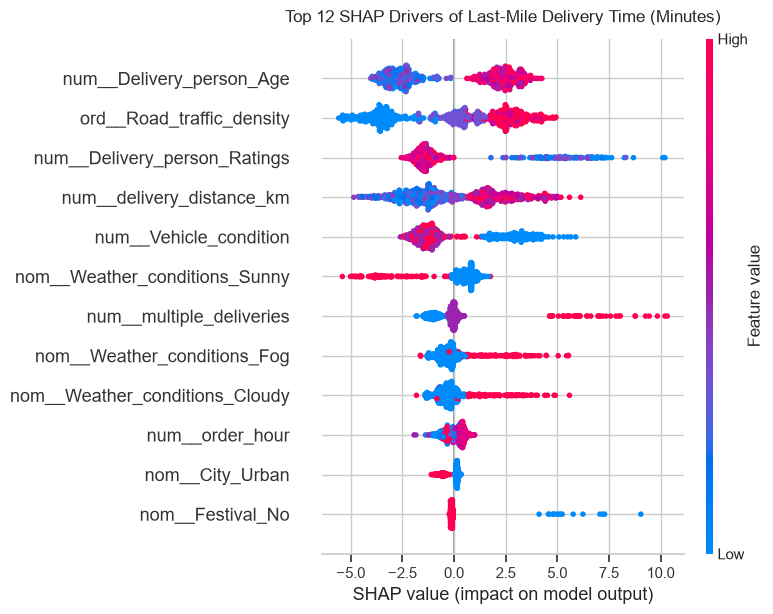

In [14]:
lgbm_pipe = models["LightGBM Regressor (ETA Engine)"]

X_test_sample = X_test.sample(800, random_state=42)
X_test_transformed = lgbm_pipe.named_steps["preprocessor"].transform(X_test_sample)
feature_names = lgbm_pipe.named_steps["preprocessor"].get_feature_names_out()

explainer = shap.TreeExplainer(lgbm_pipe.named_steps["model"])
shap_values = explainer.shap_values(X_test_transformed)

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test_transformed, feature_names=feature_names, show=False, max_display=12)
plt.title("Top 12 SHAP Drivers of Last-Mile Delivery Time (Minutes)", fontsize=12, pad=12)
plt.tight_layout()
plt.savefig("outputs/shap_delivery_time.png", dpi=150)
plt.show()

# Conservative Quantile ETA (P80 SLA) vs. Standard Mean ETA

In [15]:
lgbm_p80 = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LGBMRegressor(
        objective="quantile", alpha=0.80,
        n_estimators=500, learning_rate=0.05, num_leaves=63, max_depth=8,
        subsample=0.8, colsample_bytree=0.8, n_jobs=-1, random_state=42, verbose=-1
    )),
])
lgbm_p80.fit(X_train, y_train)

pred_mean = models["LightGBM Regressor (ETA Engine)"].predict(X_test)
pred_p80 = lgbm_p80.predict(X_test)

comp_day5 = pd.DataFrame([
    {
        "ETA_Model": "Standard Mean ETA (L2 Loss)",
        "MAE (mins)": mean_absolute_error(y_test, pred_mean),
        "On_Time_or_Early_Rate (%)": (y_test <= pred_mean).mean() * 100,
        "Late_Orders_Rate (%)": (y_test > pred_mean).mean() * 100,
        "Avg_Buffer_Added (mins)": 0.0,
    },
    {
        "ETA_Model": "Conservative P80 ETA (Quantile alpha=0.80)",
        "MAE (mins)": mean_absolute_error(y_test, pred_p80),
        "On_Time_or_Early_Rate (%)": (y_test <= pred_p80).mean() * 100,
        "Late_Orders_Rate (%)": (y_test > pred_p80).mean() * 100,
        "Avg_Buffer_Added (mins)": (pred_p80 - pred_mean).mean(),
    },
])
display(comp_day5.round(2))

,ETA_Model,MAE (mins),On_Time_or_Early_Rate (%),Late_Orders_Rate (%),Avg_Buffer_Added (mins)
0,Standard Mean ETA (L2 Loss),3.21,52.01,47.99,0.00
1,Conservative P80 ETA (Quantile alpha=0.80),4.19,78.08,21.92,3.26
